# Time Series Forecasting Explained Simply

## Every forecast is made of three ingredients

![Daily bike counts going up and down, with a smooth line through them](https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/02-trend-seasonality-noise/figures/fig_title.png)

Learn to spot them, and you know what any forecast has to get right.

**Forecasting Made Easy, Episode 2** · Richel Attafuah, GStat

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RichelCode/Youtube/blob/main/forecasting-made-easy/02-trend-seasonality-noise/trend_seasonality_noise.ipynb)

# What you will learn today

1. The **recipe** behind every time series
2. **Trend:** which way is it going?
3. **Seasonality:** what repeats, and how often?
4. **Noise:** how big are the surprises?
5. How to **take a real series apart** into these three pieces in Python
6. How to measure **how strong** each ingredient is
7. Why this decides which forecasting method you choose

No maths background needed. If you can read a chart, you can follow this.

# Quick recap: what is a time series?

A **time series** is a list of values, each with a **timestamp**, kept **in order**.

**In plain words:** it is like a diary. Shuffle the pages and every word is still there, but the story is gone.

Today we use two real time series:

| Series | How often | Period |
|---|---|---|
| **Bikes crossing the Fremont Bridge in Seattle** (a city bike counter) | Every day | Jan 2023 to Sep 2026 |
| **Temperature in Accra, Ghana** (from Episode 1) | Every hour | Aug to Oct 2026 |

# The recipe

![Trend plus seasonality plus noise adds up to a time series](https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/02-trend-seasonality-noise/figures/fig_recipe.png)

**Time series = trend + seasonality + noise**

- **Trend** (blue): the slow direction
- **Seasonality** (orange): the pattern that repeats. Here: busy weekdays, quiet weekends
- **Noise** (grey): the random surprises

**In plain words:** like a recipe with three ingredients mixed together. Forecasting starts by tasting each one.
*(This picture is made-up data, so you can see each ingredient clearly.)*

In [1]:
import sys, os
if "google.colab" in sys.modules:   # on Colab: get the libraries and the data first
    import urllib.request; os.makedirs("data", exist_ok=True)
    for f in ['data/accra_hourly_2026.csv', 'data/fremont_bridge_daily.csv']:
        if not os.path.exists(f): urllib.request.urlretrieve("https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/02-trend-seasonality-noise/" + f, f)

import warnings; warnings.filterwarnings("ignore")   # keep the screen clean
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL, MSTL

TREND, SEASON, NOISE, DATA = "#0072B2", "#D55E00", "#5A5A5A", "#1A1A1A"
plt.rcParams.update({"font.size": 15, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titlelocation": "left"})

# Step 1: load the bike data and look at it

- One row per day: the **date** and the number of **bikes** that crossed the bridge
- A column **`hours_counted`** tells us how many hours the counter was working that day
- **One day (18 April 2023)** has only 13 hours counted. It looks like a quiet day, but really the counter was broken.
  We replace it with the same weekday from the week before

**Rule:** always look before you model.

Days with a broken counter: [datetime.date(2023, 4, 18)]
1,369 days, from 01 Jan 2023 to 30 Sep 2026


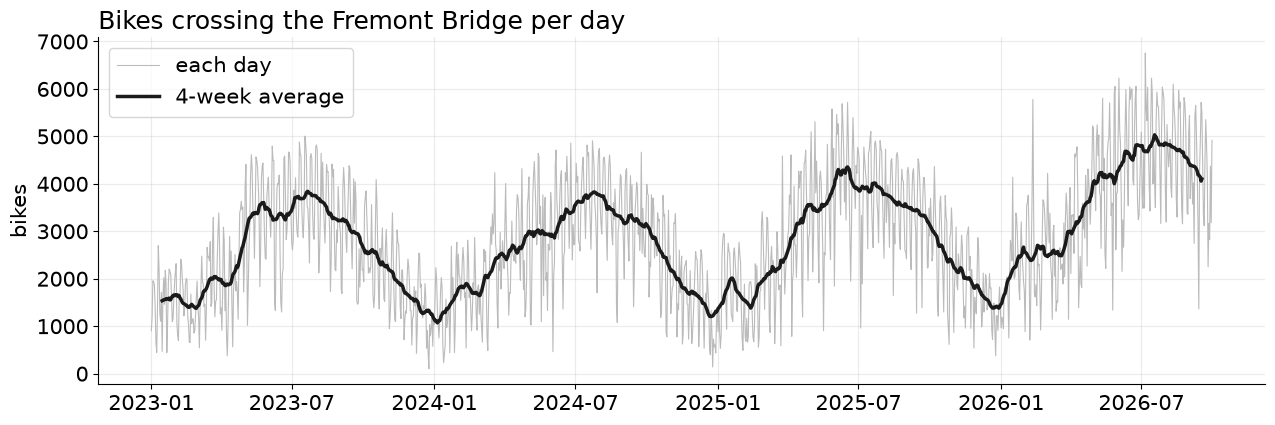

In [2]:
bikes = pd.read_csv("data/fremont_bridge_daily.csv", parse_dates=["date"], index_col="date")

broken = bikes["hours_counted"] < 23        # 23 is fine: that is the day the clocks change in March
print("Days with a broken counter:", list(bikes.index[broken].date))

y = bikes["bikes"].astype(float).mask(broken)           # remove the broken day
y = y.fillna(y.shift(7)).asfreq("D")                     # fill it with the same weekday last week
print(f"{len(y):,} days, from {y.index.min():%d %b %Y} to {y.index.max():%d %b %Y}")

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(y.index, y, color="#BBBBBB", lw=.8, label="each day")
ax.plot(y.index, y.rolling(28, center=True).mean(), color=DATA, lw=2.5, label="4-week average")
ax.set(title="Bikes crossing the Fremont Bridge per day", ylabel="bikes")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

# Ingredient 1: Trend

The **trend** is the long-run direction: **up, down or flat**. It can bend over time.

- **In plain words:** like a child growing taller. Day to day you do not notice it, but over years it is obvious
- **The question it answers:** *is the bridge busier now than it was in 2023?*

**A fair comparison:** our data stops in September 2026, so we compare **January to September** in every year.
Otherwise 2026 would be missing its quiet winter months and look busier than it really is.

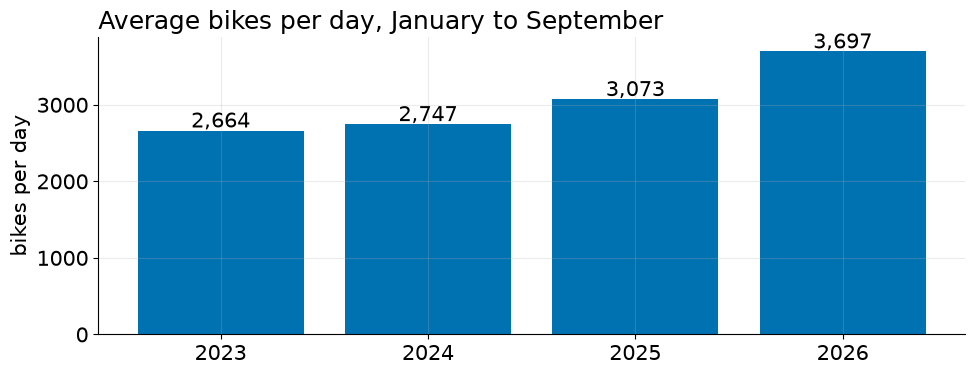

From 2023 to 2026: +39%


In [3]:
jan_to_sep = y[y.index.month <= 9]
per_year = jan_to_sep.groupby(jan_to_sep.index.year).mean()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(per_year.index.astype(str), per_year, color=TREND)
for i, v in enumerate(per_year):
    ax.text(i, v + 40, f"{v:,.0f}", ha="center", fontsize=15)
ax.set(title="Average bikes per day, January to September", ylabel="bikes per day")
plt.tight_layout(); plt.show()
print(f"From 2023 to 2026: {per_year.iloc[-1] / per_year.iloc[0] - 1:+.0%}")

# Ingredient 2: Seasonality

**Seasonality** is a pattern that **repeats on a fixed calendar cycle**. A series can have more than one:

| Cycle | Example |
|---|---|
| **Daily** (every 24 hours) | Accra is cool at dawn and hot in the afternoon |
| **Weekly** (every 7 days) | More bikes on workdays, fewer at the weekend |
| **Yearly** (every 12 months) | More bikes in the dry, warm summer, fewer in the wet winter |

**In plain words:** seasonality is the **habit** in the data. If you know the habit, you already know a lot about tomorrow.

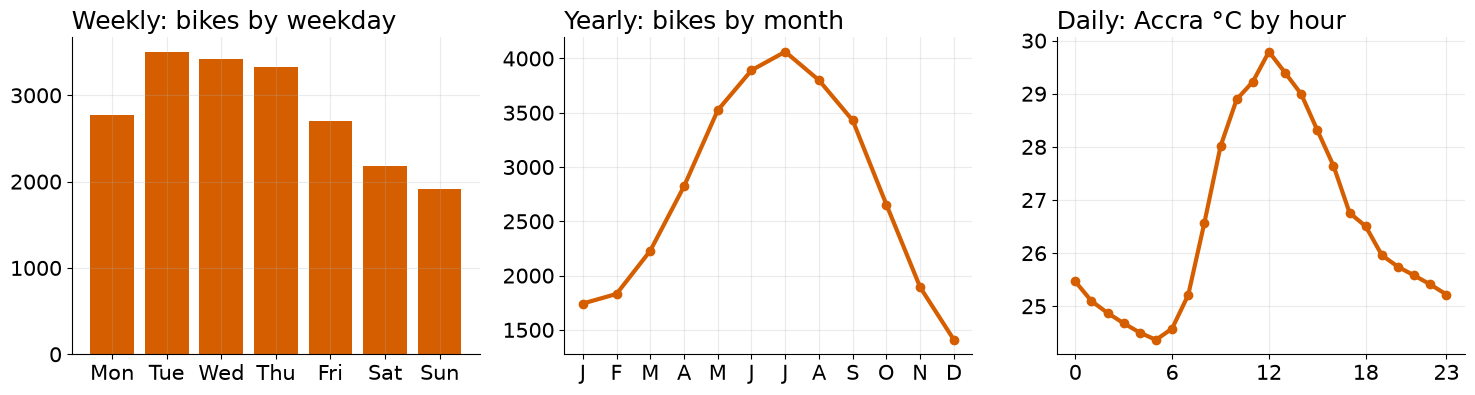

Busiest weekday has 1.8x the bikes of the quietest
Busiest month has 2.9x the bikes of the quietest


In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))

by_weekday = y.groupby(y.index.dayofweek).mean()
axs[0].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], by_weekday, color=SEASON)
axs[0].set(title="Weekly: bikes by weekday")

by_month = y.groupby(y.index.month).mean()
axs[1].plot(range(1, 13), by_month, color=SEASON, lw=3, marker="o")
axs[1].set(title="Yearly: bikes by month", xticks=range(1, 13), xticklabels=list("JFMAMJJASOND"))

temp = pd.read_csv("data/accra_hourly_2026.csv", parse_dates=["time"], index_col="time")["temperature_2m"].asfreq("h")
by_hour = temp.groupby(temp.index.hour).mean()
axs[2].plot(by_hour.index, by_hour, color=SEASON, lw=3, marker="o")
axs[2].set(title="Daily: Accra °C by hour", xticks=[0, 6, 12, 18, 23])

plt.tight_layout(); plt.show()
print(f"Busiest weekday has {by_weekday.max() / by_weekday.min():.1f}x the bikes of the quietest")
print(f"Busiest month has {by_month.max() / by_month.min():.1f}x the bikes of the quietest")

# Seasonality is not the same as a cycle

![Left: a wave that repeats with a fixed length. Right: rises and falls with no fixed length](https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/02-trend-seasonality-noise/figures/fig_season_vs_cycle.png)

- **Seasonality** has a **fixed length**: every day, every week, every year. You can put it in a calendar
- A **cycle** rises and falls with **no fixed length**, like booms and slowdowns in the economy
- Seasonality is easy to forecast. A cycle is much harder, because you do not know when the next turn comes

# Ingredient 3: Noise

**Noise** is what is left after you take out the trend and the seasonality.

- The surprises: a rainy day, a public holiday, a road closure, a sensor glitch
- You **cannot predict** each surprise. But you **can measure how big** surprises usually are
- That size decides **how wide your forecast range** should be (golden rule 2 from Episode 1: ranges beat single numbers)

**In plain words:** you cannot know which day the bus will be late, but you know it is usually 5 to 10 minutes. So you leave early.

# Taking a real series apart: STL

**STL** (Seasonal-Trend decomposition using LOESS) splits a series into the three ingredients for you.

1. Find the **repeating shape** (here: the 24-hour pattern)
2. Draw a **smooth line** through what is left. That is the **trend**
3. Whatever is still left over is the **noise**

**In plain words:** LOESS is just a careful way of drawing a smooth line through points. We tell STL one thing: **how long one cycle is** (`period=24` hours).

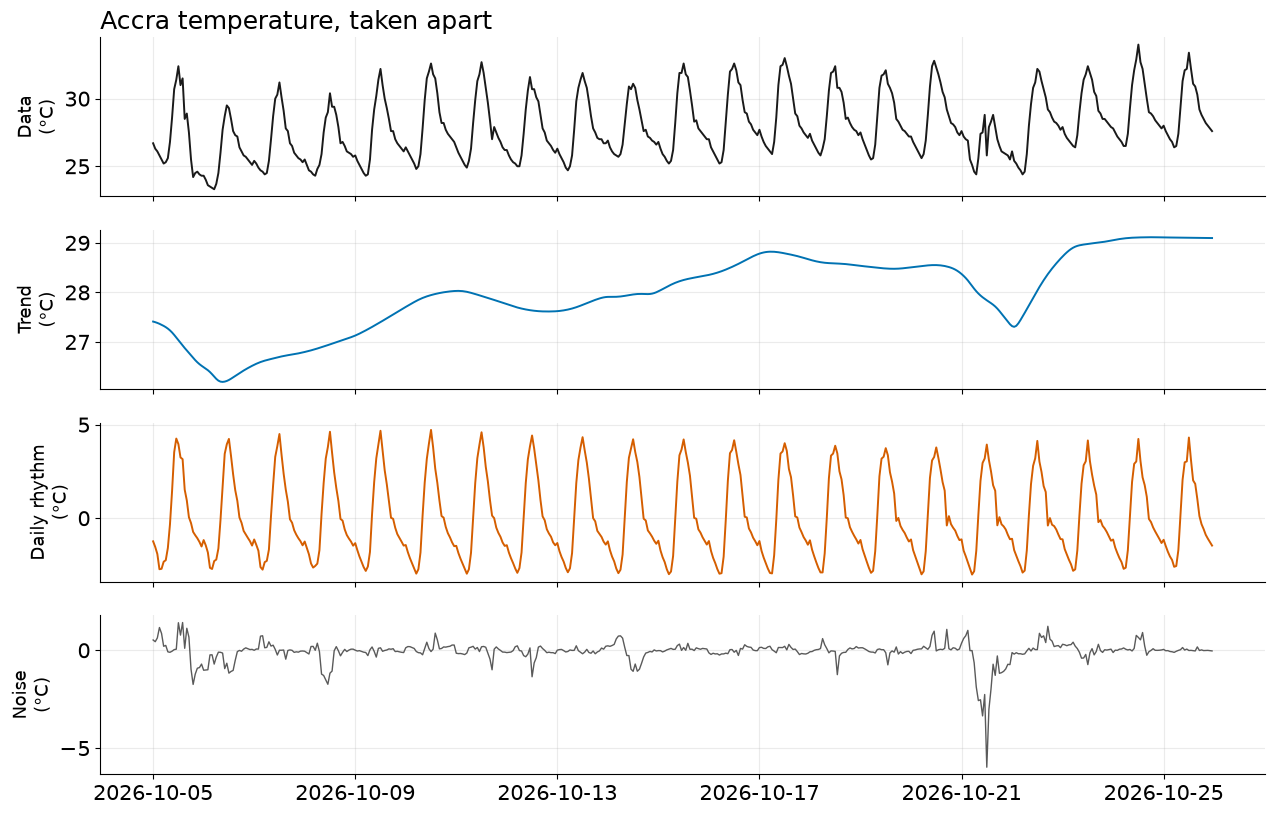

The daily rhythm: coolest hour about -2.1 °C, hottest hour about +3.2 °C (a swing of 5.4 °C)
A typical surprise (noise) is about ±0.5 °C


In [5]:
def show_parts(original, trend, seasonals, noise, unit, title):
    rows = [("Data", original, DATA), ("Trend", trend, TREND)]
    rows += [(name, s, SEASON) for name, s in seasonals.items()] + [("Noise", noise, NOISE)]
    fig, axs = plt.subplots(len(rows), 1, figsize=(13, 2.1 * len(rows)), sharex=True)
    for ax, (name, s, c) in zip(axs, rows):
        ax.plot(s.index, s, color=c, lw=1.4 if name != "Noise" else 1)
        ax.set_ylabel(f"{name}\n({unit})", fontsize=13)
    axs[0].set_title(title); plt.tight_layout(); plt.show()

accra = STL(temp, period=24, robust=True).fit()
last3 = slice(temp.index[-24 * 21], None)            # show the last 3 weeks so we can see each day
show_parts(temp[last3], accra.trend[last3], {"Daily rhythm": accra.seasonal[last3]}, accra.resid[last3],
           "°C", "Accra temperature, taken apart")
shape = accra.seasonal.groupby(accra.seasonal.index.hour).mean()       # the typical 24-hour shape
print(f"The daily rhythm: coolest hour about {shape.min():+.1f} °C, hottest hour about {shape.max():+.1f} °C (a swing of {shape.max() - shape.min():.1f} °C)")
print(f"A typical surprise (noise) is about ±{accra.resid.std():.1f} °C")

# What the Accra picture tells us

- **Trend:** the slow-moving level. In temperature it rises and falls with **weather spells** over several days
- **Daily rhythm:** a strong, very regular 24-hour wave. This is the biggest ingredient
- **Noise:** small, typically about half a degree. **The big spike on 21 October** is the unusual day from Episode 1, the day the lazy forecast got badly wrong

**For forecasting:** a model that gets the daily rhythm right is already most of the way there.
That is exactly why "same hour yesterday" was so hard to beat in Episode 1.

# Two seasons at once: MSTL

The bike data has **two** repeating patterns: **weekly** (7 days) and **yearly** (365 days).

**MSTL** (the M is for **Multiple**) is STL for several seasons. We give it both cycle lengths: `periods=[7, 365]`.

**Watch for:** the trend line, the weekly wave, the yearly wave, and the noise spikes.

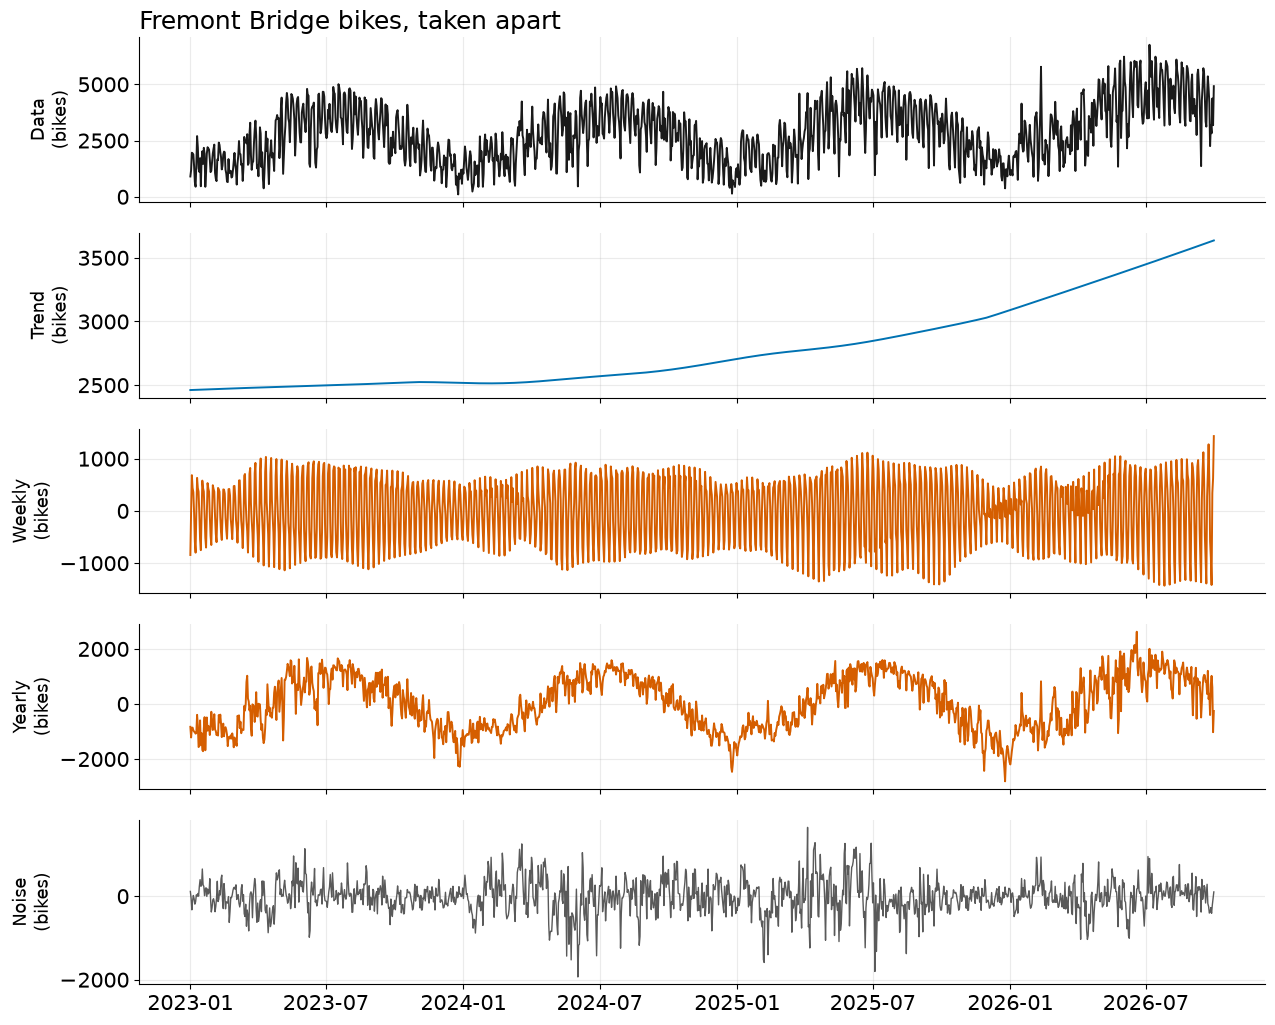

Trend: about 2,462 bikes a day in Jan 2023, about 3,636 in Sep 2026
Weekly rhythm: Sundays about -918 bikes, Tuesdays about +667
Yearly rhythm: quietest month about -1,337 bikes, busiest month about +1,204
A typical surprise (noise): about ±401 bikes


In [6]:
parts = MSTL(y, periods=[7, 365]).fit()
show_parts(y, parts.trend,
           {"Weekly": parts.seasonal["seasonal_7"], "Yearly": parts.seasonal["seasonal_365"]},
           parts.resid, "bikes", "Fremont Bridge bikes, taken apart")

print(f"Trend: about {parts.trend.iloc[0]:,.0f} bikes a day in Jan 2023, about {parts.trend.iloc[-1]:,.0f} in Sep 2026")
week = parts.seasonal["seasonal_7"].groupby(y.index.dayofweek).mean()      # the typical weekly shape
year = parts.seasonal["seasonal_365"].groupby(y.index.month).mean()         # the typical yearly shape
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
print(f"Weekly rhythm: {DAYS[week.idxmin()]}s about {week.min():+,.0f} bikes, {DAYS[week.idxmax()]}s about {week.max():+,.0f}")
print(f"Yearly rhythm: quietest month about {year.min():+,.0f} bikes, busiest month about {year.max():+,.0f}")
print(f"A typical surprise (noise): about ±{parts.resid.std():,.0f} bikes")

# What the bike picture tells us

- **Trend:** steadily **up**. More people are cycling across this bridge every year
- **Weekly:** workdays busy, weekends quiet. These are mostly **commuters**
- **Yearly:** summer high, winter low
- **Noise:** the big downward spikes are days the pattern did not hold, like **heavy rain** and **public holidays**

**For forecasting:** a good bike forecast must **follow the trend**, **copy both rhythms**, and give a **range** wide enough for the surprises.

# How strong is each ingredient?

We can give each ingredient a **strength score from 0 to 1**:

- **Close to 1:** a strong, clear pattern. The noise is small next to it
- **Close to 0:** a weak pattern, mostly drowned in noise

**How it works:** compare the size of the noise with the size of "pattern + noise".
If removing the pattern leaves only a little behind, the pattern was strong.
*(This is the measure from Hyndman and Athanasopoulos, Forecasting: Principles and Practice.)*

In [7]:
def strength(pattern, noise):
    return max(0, 1 - noise.var() / (pattern + noise).var())

scores = pd.DataFrame({
    "Accra temperature (hourly)": {"Trend": strength(accra.trend, accra.resid),
                                   "Daily rhythm": strength(accra.seasonal, accra.resid)},
    "Fremont bikes (daily)": {"Trend": strength(parts.trend, parts.resid),
                              "Weekly rhythm": strength(parts.seasonal["seasonal_7"], parts.resid),
                              "Yearly rhythm": strength(parts.seasonal["seasonal_365"], parts.resid)},
}).round(2)
scores.fillna("")

,Accra temperature (hourly),Fremont bikes (daily)
Trend,0.81,0.41
Daily rhythm,0.93,
Weekly rhythm,,0.71
Yearly rhythm,,0.85


# Reading the scores

- **Accra:** the **daily rhythm** is very strong. Copying yesterday's shape gets you far
- **Bikes:** both **weekly and yearly rhythms** are strong. The long-run trend is **weaker**: it is real, but small next to the big summer-winter swing and the rainy-day surprises
- **Neither series is mostly noise.** Both are worth forecasting

**In plain words:** these scores tell you **where to spend your effort** before you pick a model.

# One more thing: seasonality can grow

Look at the bikes in **summer** and in **winter**. Is the weekday-weekend gap the same size?

- If the gap stays the **same size**, we call the seasonality **additive**: it is *added* on top of the level
- If the gap **grows when the level grows**, it is **multiplicative**: it *scales* with the level

Many forecasting tools let you choose. Getting it right makes the ranges more honest.

In [8]:
season_of = np.select([y.index.month.isin([6, 7, 8]), y.index.month.isin([12, 1, 2])], ["Summer", "Winter"], "")
weekend = y.index.dayofweek >= 5
gap = pd.DataFrame({
    "weekday average": y[~weekend].groupby(season_of[~weekend]).mean(),
    "weekend average": y[weekend].groupby(season_of[weekend]).mean(),
}).loc[["Winter", "Summer"]]
gap["gap (bikes)"] = gap["weekday average"] - gap["weekend average"]
gap["weekend as % of weekday"] = gap["weekend average"] / gap["weekday average"] * 100
gap.round(0)

,weekday average,weekend average,gap (bikes),weekend as % of weekday
Winter,1927.0,1044.0,883.0,54.0
Summer,4293.0,2990.0,1303.0,70.0


# What we found

- In **bikes**, the gap **grows** in summer. So it is **not purely additive**
- But in **percent**, weekends are about 54% of a weekday in winter and about 70% in summer. So it is **not purely multiplicative** either
- **Real data rarely follows the textbook exactly.** That is fine: the point is to **look**, so you choose your settings with your eyes open

**In plain words:** the textbook gives you two boxes. Your data does not have to fit neatly in one.

# Why this matters for forecasting

| Ingredient | What a forecast must do | Who does it |
|---|---|---|
| **Trend** | Follow the direction | Trend models (like the T in **ETS**), AI models |
| **Seasonality** | Copy the repeating shape | Even the lazy **seasonal naive** forecast does this |
| **Noise** | Cannot be predicted, so be honest about it | A **range** (prediction interval) |

**In plain words:** most of a good forecast is **getting the trend and the habits right**, then being honest about the surprises.

# Three questions to ask before you forecast anything

1. **Which way is it going?** (trend)
2. **What repeats, and how often?** (seasonality: daily, weekly, yearly)
3. **How big are the surprises?** (noise, which sets the width of your range)

Plot the data, take it apart with **STL** or **MSTL**, and you can answer all three in a few lines of Python.

# Next episode

## Build Your First Demand Forecast in Python, Step by Step

We use the same bike data to forecast **next week's demand**, day by day, from loading the data to a forecast you can act on.

The code from today is linked in the description.